EXPLORATORY DATA ANALYSIS



In [1]:
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns

dataset=load_dataset('lukebarousse/data_jobs')
df= dataset['train'].to_pandas()
def clean_list (skill_list):
    if pd.notna(skill_list):
        return ast.literal_eval(skill_list)

df['job_skills'] = df['job_skills'].apply(clean_list)
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])


d:\Anaconda\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Filter for Indian Data Scientist roles


In [4]:
df1 = df[(df['job_country'] == 'India') & (df['job_title_short'] == 'Data Scientist')].copy()

In [5]:
df1


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
19,Data Scientist,Data Scientist,"Pune, Maharashtra, India",via Indeed,Full-time,False,India,2023-04-26 13:20:12,False,False,India,NaN,NaN,NaN,Bitwise Solutions,"[r, sql, python, scala, java, c++, hadoop, tab...","{'analyst_tools': ['tableau'], 'libraries': ['..."
29,Data Scientist,Data Scientist,"Pune, Maharashtra, India",via Exusia,Full-time,False,India,2023-03-26 13:16:20,False,False,India,NaN,NaN,NaN,Exusia,None,NaN
239,Data Scientist,Power BI Data Analytics & Data Scientist,"Maharashtra, India",via Shine,Full-time,False,India,2023-11-11 13:10:08,False,False,India,NaN,NaN,NaN,Emerson,[power bi],{'analyst_tools': ['power bi']}
323,Data Scientist,Forecasting Analyst,Anywhere,via LinkedIn,Full-time,True,India,2023-09-28 13:48:45,False,False,India,NaN,NaN,NaN,Straive,[excel],{'analyst_tools': ['excel']}
389,Data Scientist,Data Scientist,"New Delhi, Delhi, India",via LinkedIn,Contractor,False,India,2023-09-12 13:16:27,False,False,India,NaN,NaN,NaN,Digital India Corporation,"[sql, sas, sas, excel, powerpoint, tableau]","{'analyst_tools': ['sas', 'excel', 'powerpoint..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785591,Data Scientist,Data Scientist T8,"Bengaluru, Karnataka, India",via BeBee India,Full-time,False,India,2023-01-01 06:29:03,False,False,India,NaN,NaN,NaN,Mercedes-Benz Research and Development India P...,"[java, python, aws, azure, kubernetes, docker,...","{'async': ['jira', 'confluence'], 'cloud': ['a..."
785645,Data Scientist,Data Science Intern,Anywhere,via LinkedIn,Internship,True,India,2023-01-20 06:51:23,False,False,India,NaN,NaN,NaN,TwiLearn EduTech Pvt. Ltd.,"[python, tableau]","{'analyst_tools': ['tableau'], 'programming': ..."
785654,Data Scientist,Data Science Intern,Anywhere,via LinkedIn,NaN,True,India,2023-01-31 06:11:46,False,False,India,NaN,NaN,NaN,Corizo,[zoom],{'sync': ['zoom']}
785674,Data Scientist,Data Scientist,"Kolkata, West Bengal, India",via LinkedIn,Full-time,False,India,2023-01-12 06:12:32,False,False,India,NaN,NaN,NaN,One Billion Ideas Pvt. LTD.,"[r, python, sql, scala, java, c++, matplotlib,...","{'analyst_tools': ['tableau'], 'libraries': ['..."


In [10]:
df1_plot =df1['job_location'].value_counts().head(10).to_frame()



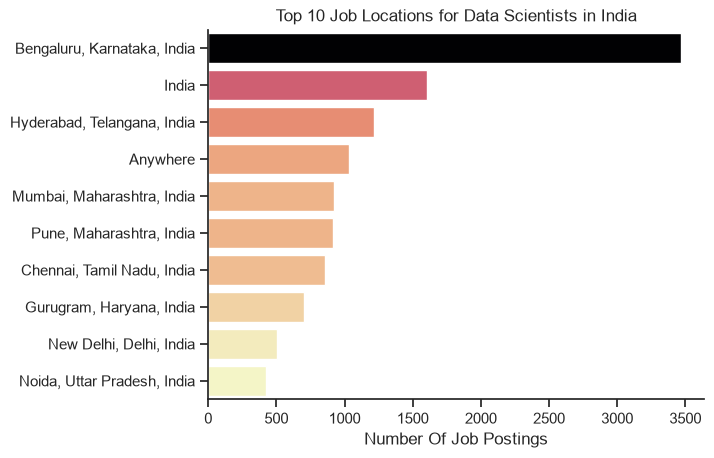

In [21]:
sns.set_theme(style='ticks')
sns.barplot(data=df1_plot, x='count', y='job_location', hue='count', palette='magma_r', legend=False)
sns.despine()
plt.title('Top 10 Job Locations for Data Scientists in India')
plt.xlabel('Number Of Job Postings')
plt.ylabel('')
plt.show()


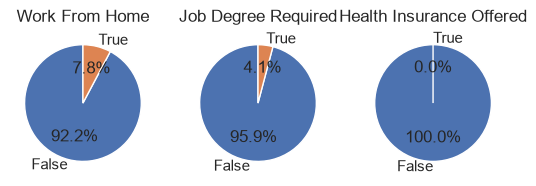

In [28]:

fig, ax = plt.subplots(1, 3)

dict_columns={
    'job_work_from_home': 'Work From Home',
    'job_no_degree_mention': 'Job Degree Required',
    'job_health_insurance': 'Health Insurance Offered'
}

for i, (column, title) in enumerate(dict_columns.items()):
    ax[i].pie(df1[column].value_counts().reindex([False, True], fill_value=0), startangle=90, autopct='%1.1f%%', labels=['False', 'True'])
    ax[i].set_title(title)

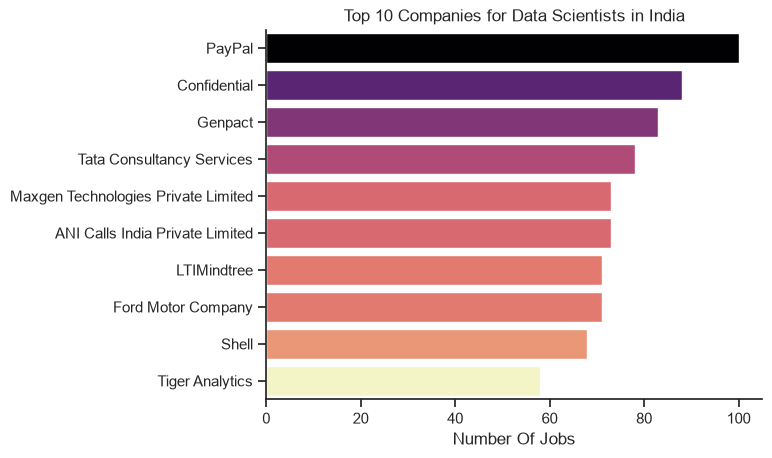

In [29]:
df2_plot =df1['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df2_plot, x='count', y='company_name', hue='count', palette='magma_r', legend=False)
sns.despine()
plt.title('Top 10 Companies for Data Scientists in India')
plt.xlabel('Number Of Jobs')
plt.ylabel('')
plt.show()